# Optional Lab: Linear Regression using Scikit-Learn

There is an open-source, commercially usable machine learning toolkit called [scikit-learn](https://scikit-learn.org/stable/index.html). This toolkit contains implementations of many of the algorithms that you will work with in this course.



## Goals
In this lab you will:
- Utilize  scikit-learn to implement linear regression using Gradient Descent

## Tools
You will utilize functions from scikit-learn as well as matplotlib and NumPy. 

In [1]:
import numpy as np
np.set_printoptions(precision=2)
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.preprocessing import StandardScaler
from lab_utils_multi import  load_house_data
import matplotlib.pyplot as plt
dlblue = '#0096ff'; dlorange = '#FF9300'; dldarkred='#C00000'; dlmagenta='#FF40FF'; dlpurple='#7030A0'; 
plt.style.use('./deeplearning.mplstyle')

# Gradient Descent
Scikit-learn has a gradient descent regression model [sklearn.linear_model.SGDRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDRegressor.html#examples-using-sklearn-linear-model-sgdregressor).  Like your previous implementation of gradient descent, this model performs best with normalized inputs. [sklearn.preprocessing.StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler) will perform z-score normalization as in a previous lab. Here it is referred to as 'standard score'.


 https://scikit-learn.org.cn/view/733.html

### Load the data set

In [2]:
X_train, y_train = load_house_data()
X_features = ['size(sqft)','bedrooms','floors','age']

### Scale/normalize the training data

In [3]:
scaler = StandardScaler()#创建实例
X_norm = scaler.fit_transform(X_train)
print(f"Peak to Peak range by column in Raw        X:{np.ptp(X_train,axis=0)}")   
print(f"Peak to Peak range by column in Normalized X:{np.ptp(X_norm,axis=0)}")

Peak to Peak range by column in Raw        X:[2.41e+03 4.00e+00 1.00e+00 9.50e+01]
Peak to Peak range by column in Normalized X:[5.85 6.14 2.06 3.69]


### Create and fit the regression model

In [4]:
sgdr = SGDRegressor(max_iter=1000)
sgdr.fit(X_norm, y_train)
print(sgdr)
print(f"number of iterations completed: {sgdr.n_iter_}, number of weight updates: {sgdr.t_}")

SGDRegressor()
number of iterations completed: 128, number of weight updates: 12673.0


### View parameters
Note, the parameters are associated with the *normalized* input data. The fit parameters are very close to those found in the previous lab with this data.

In [5]:
b_norm = sgdr.intercept_
w_norm = sgdr.coef_
print(f"model parameters:                   w: {w_norm}, b:{b_norm}")
print(f"model parameters from previous lab: w: [110.56 -21.27 -32.71 -37.97], b: 363.16")

model parameters:                   w: [110.18 -21.08 -32.52 -38.03], b:[363.15]
model parameters from previous lab: w: [110.56 -21.27 -32.71 -37.97], b: 363.16


In [6]:
X_norm.shape

(99, 4)

In [7]:
np.set_printoptions(precision=5,suppress=True)

In [8]:
w_norm.shape

(4,)

In [9]:
b_norm

array([363.14861])

### Make predictions
Predict the targets of the training data. Use both the `predict` routine and compute using $w$ and $b$.

In [10]:
# make a prediction using sgdr.predict()
y_pred_sgd = sgdr.predict(X_norm)
# make a prediction using w,b. 
y_pred = np.dot(X_norm, w_norm) + b_norm  
print(f"prediction using np.dot() and sgdr.predict match: {(y_pred == y_pred_sgd).all()}")

print(f"Prediction on training set:\n{y_pred[:4]}" )
print(f"Target values \n{y_train[:4]}")

prediction using np.dot() and sgdr.predict match: True
Prediction on training set:
[295.20551 485.84232 389.54076 492.00469]
Target values 
[300.  509.8 394.  540. ]


In [11]:
y_pred.shape

(99,)

In [12]:
X_train

array([[1244.,    3.,    1.,   64.],
       [1947.,    3.,    2.,   17.],
       [1725.,    3.,    2.,   42.],
       [1959.,    3.,    2.,   15.],
       [1314.,    2.,    1.,   14.],
       [ 864.,    2.,    1.,   66.],
       [1836.,    3.,    1.,   17.],
       [1026.,    3.,    1.,   43.],
       [3194.,    4.,    2.,   87.],
       [ 788.,    2.,    1.,   80.],
       [1200.,    2.,    2.,   17.],
       [1557.,    2.,    1.,   18.],
       [1430.,    3.,    1.,   20.],
       [1220.,    2.,    1.,   15.],
       [1092.,    2.,    1.,   64.],
       [ 848.,    1.,    1.,   17.],
       [1682.,    3.,    2.,   23.],
       [1768.,    3.,    2.,   18.],
       [1040.,    3.,    1.,   44.],
       [1652.,    2.,    1.,   21.],
       [1088.,    2.,    1.,   35.],
       [1316.,    3.,    1.,   14.],
       [1593.,    0.,    1.,   20.],
       [ 972.,    2.,    1.,   73.],
       [1097.,    3.,    1.,   37.],
       [1004.,    2.,    1.,   51.],
       [ 904.,    3.,    1.,   55.],
 

In [19]:
X_train[:,1]

array([3., 3., 3., 3., 2., 2., 3., 3., 4., 2., 2., 2., 3., 2., 2., 1., 3.,
       3., 3., 2., 2., 3., 0., 2., 3., 2., 3., 3., 2., 3., 3., 3., 2., 4.,
       2., 3., 3., 3., 2., 3., 4., 4., 2., 3., 3., 2., 3., 2., 3., 3., 3.,
       2., 3., 3., 2., 3., 3., 3., 3., 2., 3., 2., 3., 3., 3., 3., 2., 4.,
       3., 3., 4., 3., 3., 3., 3., 3., 3., 3., 2., 2., 3., 3., 3., 2., 3.,
       3., 4., 3., 3., 2., 3., 3., 3., 3., 2., 2., 3., 3., 2.])

In [20]:
X_train[:,2]

array([1., 2., 2., 2., 1., 1., 1., 1., 2., 1., 2., 1., 1., 1., 1., 1., 2.,
       2., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 2., 1., 2., 2., 2.,
       1., 2., 2., 2., 2., 2., 2., 2., 1., 1., 2., 2., 1., 1., 1., 1., 1.,
       1., 1., 2., 1., 2., 2., 1., 1., 2., 1., 1., 1., 1., 2., 1., 1., 2.,
       1., 2., 2., 2., 1., 1., 1., 2., 2., 1., 1., 1., 1., 2., 2., 1., 2.,
       1., 2., 1., 1., 1., 2., 1., 1., 1., 2., 1., 2., 1., 1.])

In [21]:
y_train

array([300.   , 509.8  , 394.   , 540.   , 415.   , 230.   , 560.   ,
       294.   , 718.2  , 200.   , 302.   , 468.   , 374.2  , 388.   ,
       282.   , 311.8  , 401.   , 449.8  , 301.   , 502.   , 340.   ,
       400.282, 572.   , 264.   , 304.   , 298.   , 219.8  , 490.7  ,
       216.96 , 368.2  , 280.   , 526.87 , 237.   , 562.426, 369.8  ,
       460.   , 374.   , 390.   , 158.   , 426.   , 390.   , 277.774,
       216.96 , 425.8  , 504.   , 329.   , 464.   , 220.   , 358.   ,
       478.   , 334.   , 426.98 , 290.   , 463.   , 390.8  , 354.   ,
       350.   , 460.   , 237.   , 288.304, 282.   , 249.   , 304.   ,
       332.   , 351.8  , 310.   , 216.96 , 666.336, 330.   , 480.   ,
       330.3  , 348.   , 304.   , 384.   , 316.   , 430.4  , 450.   ,
       284.   , 275.   , 414.   , 258.   , 378.   , 350.   , 412.   ,
       373.   , 225.   , 390.   , 267.4  , 464.   , 174.   , 340.   ,
       430.   , 440.   , 216.   , 329.   , 388.   , 390.   , 356.   ,
       257.8  ])

### Plot Results
Let's plot the predictions versus the target values.

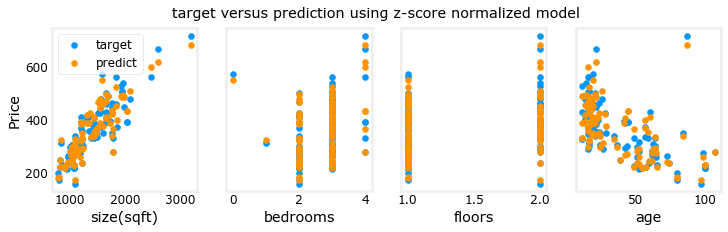

In [22]:
# plot predictions and targets vs original features    
fig,ax=plt.subplots(1,4,figsize=(12,3),sharey=True)#sharey=True 则共享坐标轴y
for i in range(len(ax)):
    ax[i].scatter(X_train[:,i],y_train, label = 'target')
    ax[i].set_xlabel(X_features[i])
    ax[i].scatter(X_train[:,i],y_pred,color=dlorange, label = 'predict')
ax[0].set_ylabel("Price"); ax[0].legend();
fig.suptitle("target versus prediction using z-score normalized model")
plt.show()

## Congratulations!
In this lab you:
- utilized an open-source machine learning toolkit, scikit-learn
- implemented linear regression using gradient descent and feature normalization from that toolkit